Equação da reta: PREÇO MÉDIO = 0.1207 * ANO + (-238.9595)
Variação estimada do preço médio por ano de lançamento: 0.12

Métricas da regressão:
Coeficiente de determinação (R²): 0.6715
Erro quadrático médio (MSE): 0.5341


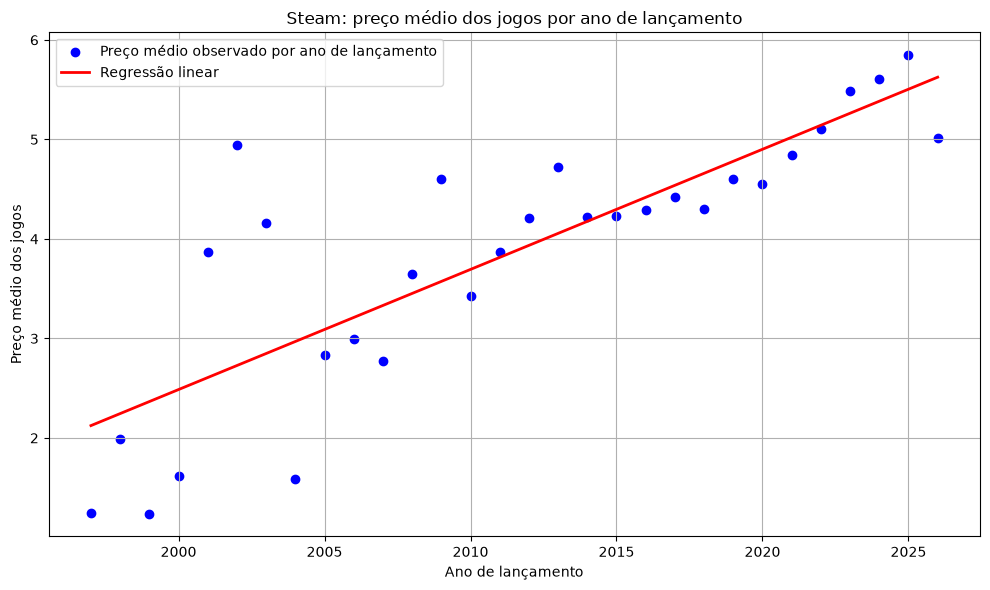

In [1]:
import polars as pl
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df_reg = (
    pl.scan_parquet("steam_2026_organizada_PANDAS.parquet")
    .select(
        pl.col("Lançamento").dt.year().alias("ANO"),
        pl.col("Preço")
    )
    .drop_nulls()
    .group_by("ANO")
    .agg(pl.col("Preço").mean().alias("PRECO_MEDIO"))
    .sort("ANO")
    .collect()
)

X = df_reg["ANO"].to_numpy().reshape(-1, 1)
y = df_reg["PRECO_MEDIO"].to_numpy()

modelo = LinearRegression()
modelo.fit(X, y)

inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_

print(
    f"Equação da reta: PREÇO MÉDIO = "
    f"{inclinacao:.4f} * ANO + ({intercepto:.4f})"
)
print(f"Variação estimada do preço médio por ano de lançamento: {inclinacao:.2f}")

# 4. Calcular os valores estimados
y_pred = modelo.predict(X)

r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print("\nMétricas da regressão:")
print(f"Coeficiente de determinação (R²): {r2:.4f}")
print(f"Erro quadrático médio (MSE): {mse:.4f}")

plt.figure(figsize=(10, 6))

plt.scatter(
    X.ravel(), y,
    color="blue",
    label="Preço médio observado por ano de lançamento"
)

plt.plot(
    X.ravel(), y_pred,
    color="red",
    linewidth=2,
    label="Regressão linear"
)

plt.title("Steam: preço médio dos jogos por ano de lançamento")
plt.xlabel("Ano de lançamento")
plt.ylabel("Preço médio dos jogos")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()